# Dynamic Focal forces on the CD8 joint trajectory G (Armstrong + Clone 13)

Per fate branch of the joint STREAM2 tree **G** (`stream/runs2/Joint_sweep/_top_G`), root -> **Mem** and root -> **Exh-Term**:
the stacked bars are the authors' state composition of each dictys window (authors' UMAP colours), the **red dashed line** is the
composition speed v (its minima = attractor states) and the **black line** is the total Focal force.

Pipeline (`EarthRL/dynamic_focal/`, config `config_cd8.sh`):

1. **Windows**: dictys sliding windows on the G tree (116 windows, `NCELL_FRAC=0.045`, `NOVERLAP_FRAC=0.75`).
2. **Unmatched RNA / ATAC paired by OT**: the moscot couplings (`stream/pairing_constrained/T_<sample>.npy`, top-50 ATAC cells per RNA cell, column-normalised) give every RNA cell an accessibility profile; peak-to-gene links within +-250 kb (weight exp(-d / 50 kb)).
3. **Motif scan**: HOCOMOCO v11 mouse PFMs, tangermeme FIMO on GPU, over the scPrinter peaks (mm10).
4. **Masks + GRNs**: per window binding -> TSS distance -> linking -> binlinking mask, dictys `reconstruct` (GPUs on Delta and CRC), then normalize / indirect -> `net_iweight`, assembled into `G/dictys/output/dynamic.h5`.
5. **Forces and attractors** (`branch_attractors.py`, `earthrl.attractors.Attractor`), described in the next section.

## How the curves are made

- **Link force** in window w (Focal's `_forces.py` formula): `F = sign(beta) * exp(log10|beta| + log10 TF)`, beta from `net_iweight`, TF = log2(CPM + 1) of the TF in the window pseudobulk (raw counts summed over the window's cells).
  Note `exp(log10 a + log10 b) = (a b)^(1/ln 10) ~ (a b)^0.43`, a compressive power of beta x TF, as in Focal.
- **Links kept**: TF -> target pairs present in every window of the branch; the 20,000 with the largest peak |F| along the branch.
- **Black line**: per window the sum of |F| over those links, Gaussian kernel-smoothed over window position (bandwidth 1.5 windows, 400-point grid).
- **Red line**: the authors' state fractions per window smoothed with the same kernel; v = 0.5 * sum over states |dp/dx| (% points of composition changing per window). Local minima of v = attractor states (slow composition change).

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
FOCAL_DIR = Path("/projects/bhdw/asachan/methods/reversing_attractors/EarthRL/dynamic_focal")
sys.path.insert(0, str(FOCAL_DIR))
from branch_attractors import panel          # the plotting of the run's force_vs_speed_G figure
from earthrl.attractors import Attractor
%matplotlib inline
pd.set_option("display.width", 200, "display.max_colwidth", 200)
ROOT = Path("/work/hdd/bhdw/asachan/multiomic_datasets/cd8_eff_mem_exh/focal")
A = ROOT / "analysis"
# authors' UMAP colours: tab20 sampled at the 18 sorted authors' states (stream/02_prep_rna.py)
states = sorted(pd.read_csv("/work/hdd/bhdw/asachan/multiomic_datasets/cd8_eff_mem_exh/stream/export/scRNA_meta.tsv",
                            sep="\t", usecols=["ClusterNames"])["ClusterNames"].astype(str).unique())
PALETTE = {s: plt.get_cmap("tab20", len(states))(i) for i, s in enumerate(states)}
BRANCHES = {"Mem": "root -> Mem", "Exh": "root -> Exh-Term"}
att = {b: Attractor.load(A / "G" / b / "attractor.pkl") for b in BRANCHES}
met = pd.read_csv(A / "branch_metrics.csv").set_index("branch")

## Branch metrics

`rho_*`: Spearman of the black line (or |d black / dx|, or link-peak density) against v on the smoothed grid; `speed_min_to_force_*`: mean distance (windows) from each attractor to the nearest force minimum / peak; `expected_order_rho`: order of the expected states' composition peaks along the branch.

In [2]:
display(met.T)

branch,Mem,Exh
trajectory,G,G
root,S0,S0
leaf,S4,S3
n_windows,52,52
n_links,20000,20000
n_attractors,5,6
rho_total_force_vs_speed,-0.247765,0.136406
rho_dtotal_force_vs_speed,0.034418,0.23345
rho_peak_density_vs_speed,-0.086316,0.325687
speed_min_to_force_min_windows,2.428571,2.109023


## Total force vs composition speed, per branch

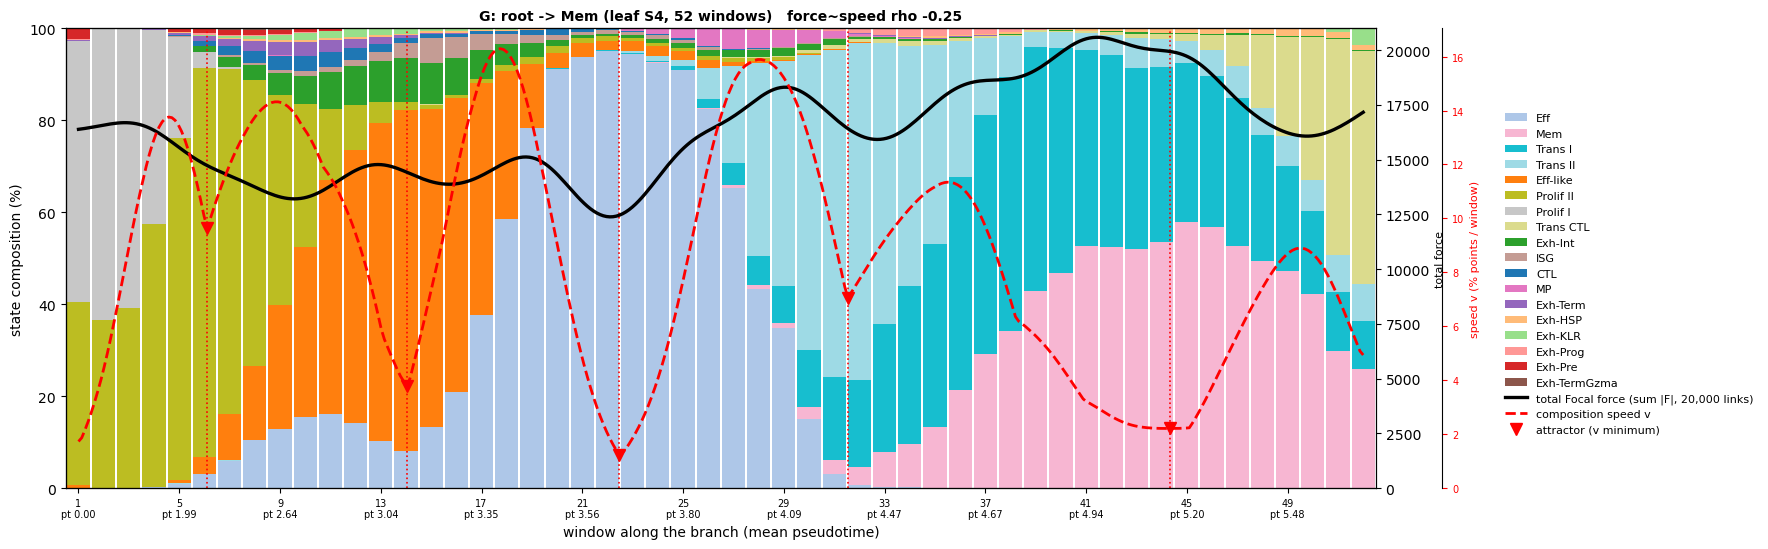

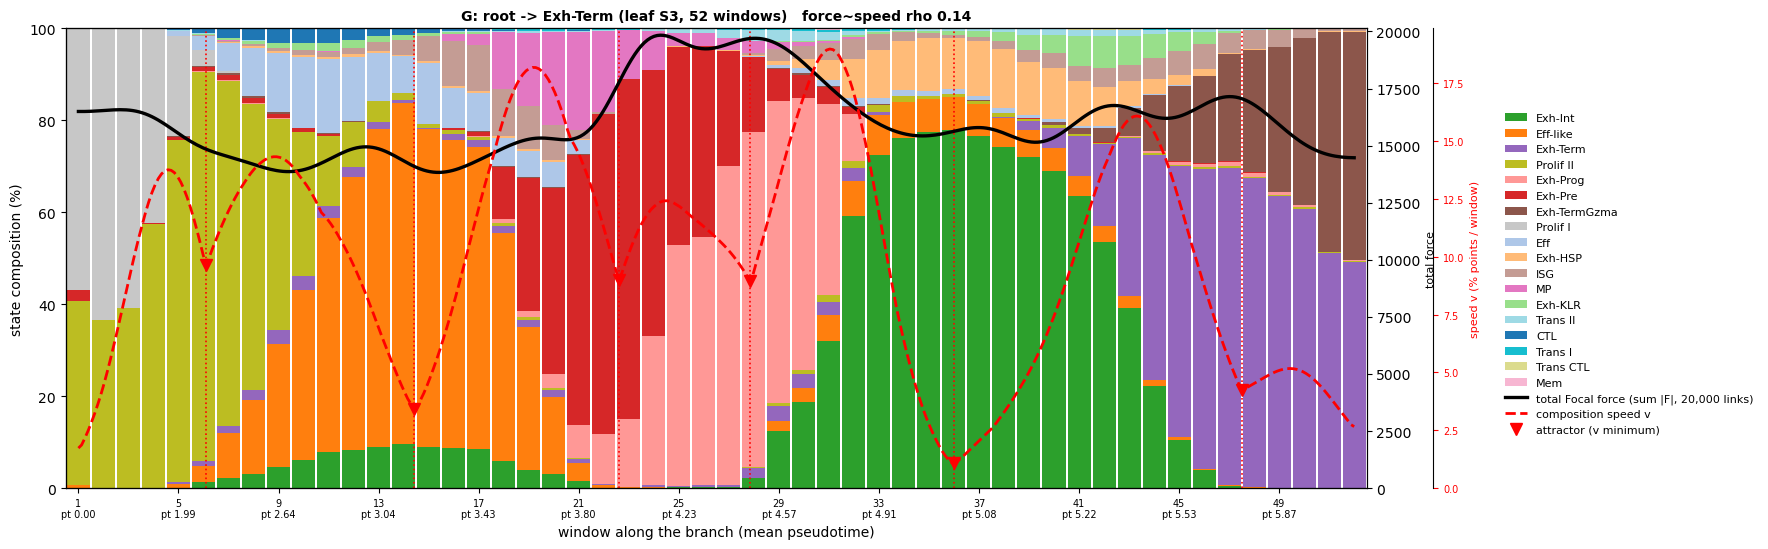

In [3]:
for b, title in BRANCHES.items():
    a, m = att[b], met.loc[b]
    fig, ax = plt.subplots(figsize=(15, 5.6))
    handles = panel(ax, a, "G: {} (leaf {}, {} windows)   force~speed rho {:.2f}".format(title, m.leaf, m.n_windows,
                                                                                    m.rho_total_force_vs_speed), PALETTE)
    step = 4                                                            # thin the window / pseudotime labels
    ax.set_xticks(a.positions[::step])
    ax.set_xticklabels(["{}\npt {:.2f}".format(i + 1, p) for i, p in zip(a.positions[::step].astype(int), a.pseudotime[::step])], fontsize=7)
    ax.set_xlabel("window along the branch (mean pseudotime)")
    bars = [h for h, l in zip(*ax.get_legend_handles_labels()) if l in a.states]
    present = [l for l in ax.get_legend_handles_labels()[1] if l in a.states]
    fig.legend(bars + handles, present + [h.get_label() for h in handles], loc="center left", bbox_to_anchor=(1.0, 0.5),
               frameon=False, fontsize=8)
    fig.tight_layout(); plt.show()

## Which states the attractors correspond to

Dominant authors' state of the smoothed composition at each speed minimum, and each attractor's span (`window_start`-`window_end`, 1-based window positions on the grid).

In [4]:
for b, title in BRANCHES.items():
    a = att[b]
    s = pd.read_csv(A / "G" / b / "attractor_states.csv")
    g = a.grid
    s["dominant_state"] = ["{} ({:.0f}%)".format(a.states[int(np.argmax(f))], f.max())
                           for f in (a.smooth_fractions[np.argmin(np.abs(g - mn))] for mn in a.minima)]
    s["speed_minimum_window"] = s["speed_minimum_window"] + 1
    print(title); display(s[["attractor_state", "speed_minimum_window", "dominant_state", "window_start", "window_end", "n_links"]].round(1))

root -> Mem


,attractor_state,speed_minimum_window,dominant_state,window_start,window_end,n_links
0,1,7.1,Prolif II (71%),1.0,10.1,443
1,2,15.0,Eff-like (67%),10.1,18.3,1865
2,3,23.5,Eff (93%),18.3,27.0,3263
3,4,32.5,Trans II (65%),27.0,37.9,8319
4,5,45.3,Mem (54%),37.9,52.0,6110


root -> Exh-Term


,attractor_state,speed_minimum_window,dominant_state,window_start,window_end,n_links
0,1,7.1,Prolif II (71%),1.0,10.3,364
1,2,15.4,Eff-like (68%),10.3,18.5,2471
2,3,23.6,Exh-Pre (62%),18.5,25.2,5218
3,4,28.8,Exh-Prog (64%),25.2,31.9,7289
4,5,37.0,Exh-Int (76%),31.9,41.8,4177
5,6,48.5,Exh-Term (65%),41.8,52.0,481


## What makes up the black line: top TFs

The black line is a sum over links; grouping the 20,000 links by TF shows which regulators carry it. Heatmap: per-window sum of |F| of each of the 20 TFs with the largest total, scaled per TF to its maximum; red ticks = attractors.

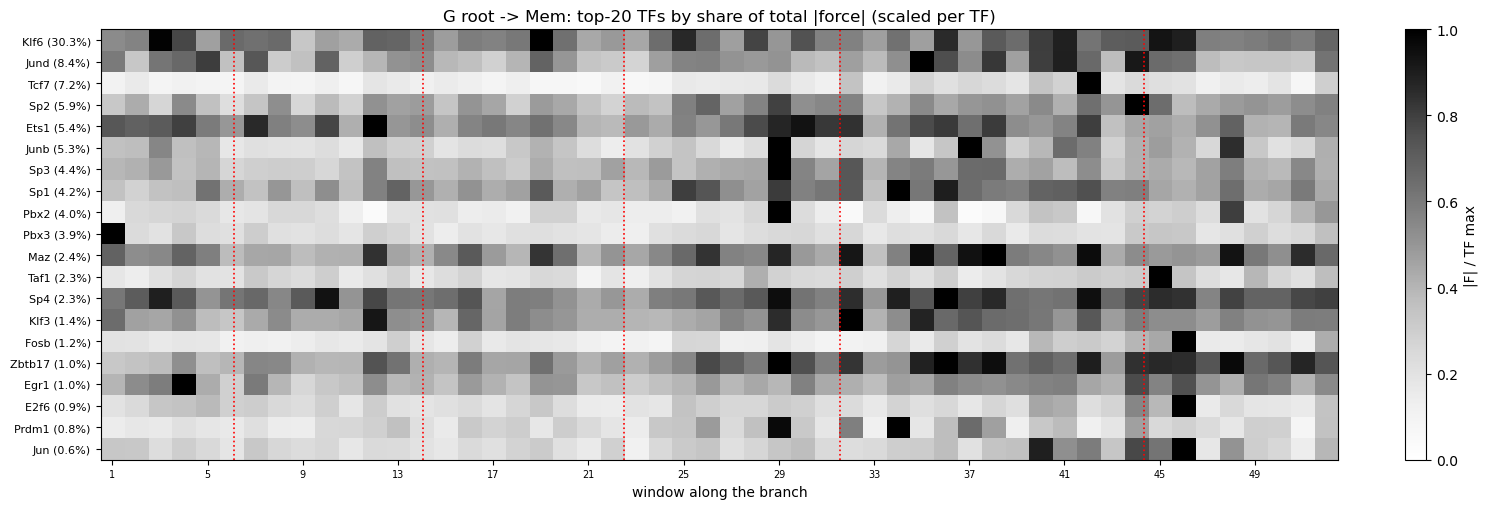

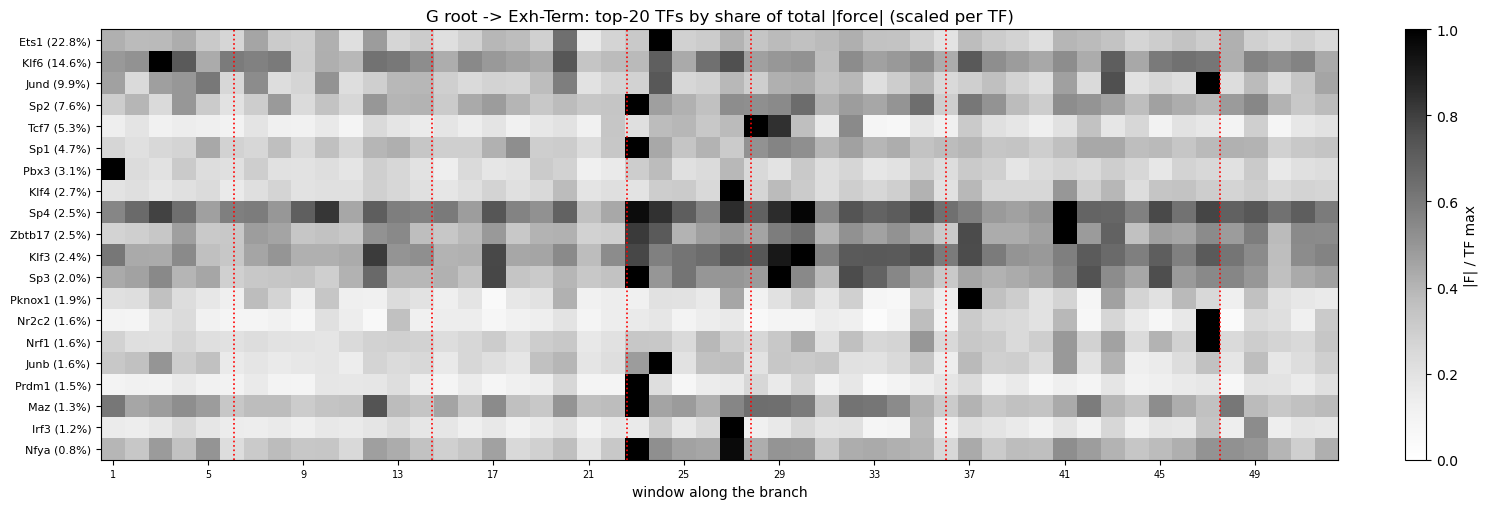

In [5]:
for b, title in BRANCHES.items():
    a = att[b]
    per_tf = pd.DataFrame(np.abs(a.link_forces), index=a.tfs).groupby(level=0).sum()
    share = per_tf.sum(axis=1) / per_tf.to_numpy().sum()
    top = share.sort_values(ascending=False).index[:20]
    h = per_tf.loc[top]
    h = h.div(h.max(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(15, 5.2))
    im = ax.imshow(h.to_numpy(), aspect="auto", cmap="Greys", vmin=0, vmax=1)
    ax.set_yticks(range(len(top))); ax.set_yticklabels(["{} ({:.1%})".format(t, share[t]) for t in top], fontsize=8)
    ax.set_xticks(a.positions[::4]); ax.set_xticklabels((a.positions[::4] + 1).astype(int), fontsize=7)
    for mn in a.minima:
        ax.axvline(mn, color="red", ls=":", lw=1.2)
    ax.set(title="G {}: top-20 TFs by share of total |force| (scaled per TF)".format(title), xlabel="window along the branch")
    fig.colorbar(im, ax=ax, fraction=0.02, label="|F| / TF max"); fig.tight_layout(); plt.show()

## Reading

- **Attractors follow the authors' states in the expected order on both branches** (`expected_order_rho` = 1). Exh branch: Prolif II -> Eff-like -> Exh-Pre -> Exh-Prog -> Exh-Int -> Exh-Term, one attractor per stage, with the Tcf7+Tox+ precursors right after the split (Giles et al. 2022, Nat Immunol). Mem branch: Prolif II -> Eff-like -> Eff -> Trans II -> Mem; Trans I has no separate minimum, and the last windows turn Trans CTL (the Tcf7-low tail of G's Mem leaf).
- **The total force does not track v globally** (rho -0.25 Mem, +0.14 Exh), and a ~2-window distance from attractors to force extrema is about what random placement gives for 5-6 attractors over 52 windows.
- **Locally the force moves with the state switches**: on the Exh branch it rises steeply into Exh-Pre / Exh-Prog and drops at the switch to Exh-Int; on the Mem branch it is lowest in the Eff block and peaks in early Mem. Total force reads as the amount of regulation being re-wired in a stretch, not as an attractor marker by itself.